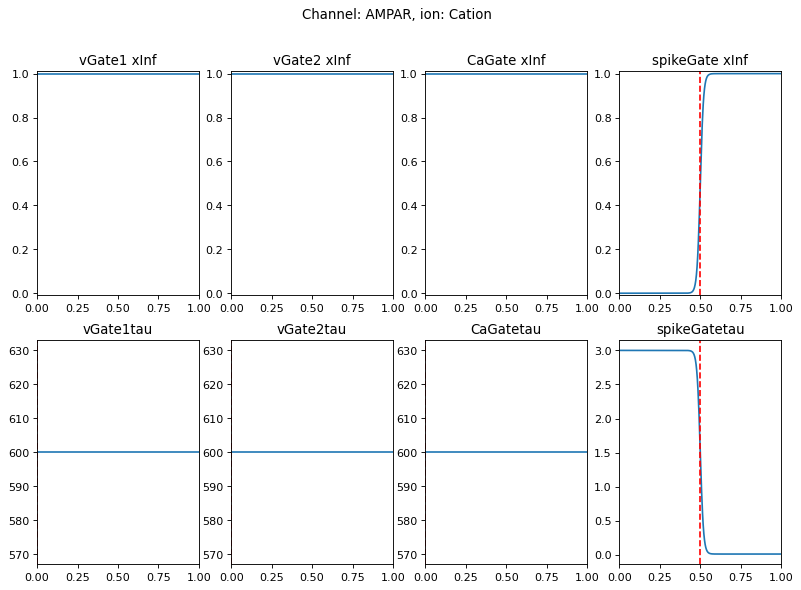

In [2]:
import numpy as np
import matplotlib.pyplot as plt

#we use inverse slope, 1/k, whereas most of the literature uses k. This is because we want to avoid division in the sigmoid function
def genGate(vHalf,vKi,tau0,tau1,th,tkInv,x0=0.0,exponent=1,minOpenness=0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,"th":th,"tkInv":tkInv,"exponent":exponent,"minOpenness":minOpenness}

def genOpenGate():
    return genGate(-1000,1000,100,1000,0,0,x0=1)

def genSynapseGate(xt1,TS):
    xt0 = TS
    xt1 = xt1-xt0
    return genGate(0.5,100,xt0,xt1,0.5,-100)


def genDefaultPlasticSynapseData(gain):
    return {
        "efficacy": 0, #p, unitless
        "conductanceGain": gain, #
        "rate": 0.05, #ms
        "gammaP": 0.12, #p per ms
        "gammaD": 0.078, #p per ms
        "thetaP": 0.68, #Ca mol/L
        "thetaD": 0.33, #Ca mol/L
    }

def genAMPA(TS):
    #for the synapses to work properly you need to know TS
    #This lets the conductance go instantly from 0 to 1
    #I wonder if this will cause instability?
    #If this doesnt work I'll have to implement a more expensive second order ODE
    gain = 10
    AMPA = {"name":"AMPAR",
                "ion":"Cation",
            "Erev": 0,
            "conductance": gain,
            "current":0,
            "CaCurrent": 0,
            "gates":{
            "vGate1":genOpenGate(),
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genSynapseGate(3,TS)}}
    for key,val in genDefaultPlasticSynapseData(gain).items():
        AMPA[key] = val
    return AMPA


def sigmoid(z,h,kInv,minOp):
    return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))

def examineGate(gateInfo,valRange,gateName,ax=None):
    gRange = [min(valRange),max(valRange)]
    vH,vK = gateInfo["vHalf"],gateInfo["vKi"]
    tau0,tau1,th,tkInv = gateInfo["tau0"],gateInfo["tau1"],gateInfo["th"],gateInfo["tkInv"]
    minOp = gateInfo["minOpenness"]
    

    xInf = sigmoid(valRange,vH,vK,minOp)
    tau = tau0 + tau1*sigmoid(valRange,th,tkInv,0)
    if ax == None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    else:
        ax[0].plot(valRange,xInf)
        ax[0].axvline(vH,color="r",linestyle="--")
        ax[0].set_title(f"{gateName} xInf")
        ax[0].set_xlim(gRange)
        #x[0].set_ylabel("Gate opening")
        ax[0].set_ylim(-0.01,1.01)

        ax[1].plot(valRange,tau)
        ax[1].axvline(th,color="r",linestyle="--")
        ax[1].set_title(f"{gateName}tau")
        #ax[1].set_ylabel("Time constant (ms)")
        ax[1].set_xlim(gRange)
    
    return xInf

def examineChannel(channel,s0=-100,s1=100):
    fig,ax = plt.subplots(2,4,figsize=(12,8), dpi=80)
    fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    valRange = np.linspace(s0,s1,501)
    netOpening = 1
    for i,(gate,gateData) in enumerate(channel["gates"].items()):
        exponent = gateData["exponent"]
        xInf = examineGate(gateData,valRange,gate,[ax[0,i],ax[1,i]])
        netOpening *= xInf**exponent

    # fig,ax = plt.subplots(1,1,dpi=90,figsize=[7,4])
    # ax.plot(valRange,netOpening)


TS=0.01
amp = genAMPA(TS)

examineChannel(amp,0,1)

In [ ]:
def genOtsukaGate(vHalf,vKi,tau0,tau1,tau2,th1,tkInv1,th2,thInv2,x0=0.0,exponent=1,minOpenness=0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,
            "tau2":tau2,"th1":th1,"tkInv1":tkInv1,"th2":th2,"tkInv2":thInv2,
            "exponent":exponent,"minOpenness":minOpenness}


def OtsukaTauSigmoid(v,tau0,tau1,tau2,theta0,theta1,kInv0,kInv1):
    return tau0 + tau1/(np.exp(-(v-theta0)*kInv0) + tau2*np.exp(-(v-theta1)*kInv1))

# KvOts,K,n,4,-41,-14,1,11,1,-40,-40,-40,50,1,0,3,Otsuka
# NavOts,Na,m,3,-40,-8,0.2,3,0,-53,0,-0.7,1,22.29,0,3,Otsuka
# NavOts,Na,h,1,-45.5,6.4,0.1,24.5,1,-50,-50,-15,16,22.29,0,3,Otsuka
# KAOts,K,a,2,-45,-14.7,1,1,0,-40,0,-0.5,0,633.5,0,3,Otsuka
# KAOts,K,b,1,-90,7.5,0,200,1,-60,-40,-30,10,633.5,0,3,Otsuka
# CaTOts,Ca,p,2,-56,-6.7,5,0.33,1,-27,-102,-10,15,585.01,0,3,Otsuka
# CaTOts,Ca,q,1,-85,5.8,0,400,1,-50,-50,-15,16,585.01,0,3,Otsuka

STNgates = {
    "n":genOtsukaGate(-41,-1/14,0,11,1,-40,-40,-1/40,-1/50),
    "m":genOtsukaGate(-40,-1/8,0.2,3,0,-53,0,-1/7,0),
    "h":genOtsukaGate(-45.5,1/6.4,0,24.5,1,-50,-50,-1/15,-1/16),
    "a":genOtsukaGate(-45,-1/14.7,1,1,0,-40,0,-1/0.5,0),
    "b":genOtsukaGate(-90,1/7.5,0,200,1,-60,-40,-1/30,-1/10),
    "p":genOtsukaGate(-56,-1/6.7,5,0.33,1,-27,-102,-1/10,-1/15),
    "q":genOtsukaGate(-85,1/5.8,0,400,1,-50,-50,-1/15,-1/16),
    
    "r":genOtsukaGate(1.7e-4,-8e-5,2,0,0,0,0,0,0), #Ca dependent
    "d1":genOtsukaGate(-60,7.5,400,500,1,-40,-20,-15,20),
    "d2":genOtsukaGate(1e-4,2e-5,130,0,0,0,0,0,0,0), #Ca dependent
}
